# La capacidad de contrapeso: recortes, capacidad de monetización y pérdidas en cartera a vencimiento

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular el valor de liquidez de una clase de activos (valor de mercado, menos la parte gravada, menos un recorte) y decir qué regla dio cada recorte;
- convertir los valores de liquidez en una capacidad de contrapeso (CBC) que crece día a día con un calendario de monetización;
- medir cómo la pérdida no realizada de una cartera mantenida a vencimiento (HTM) quita CBC y acorta el período de supervivencia;
- leer las pruebas del producto sobre las reglas de recorte, sobre el efecto HTM y sobre la revaluación de la cartera HTM, con la versión del motor que las calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `data/derived/C16/list-adverse.json`: las clases del CBC al valor contable de los valores (la base de costo amortizado), las convenciones de los recortes y del calendario de monetización, y el período de supervivencia.
- `data/derived/C16/htm-losses.json`: la misma escalera con la cartera de valores a valor razonable, el efecto de la pérdida sobre el CBC y las pruebas versionadas.

Los recortes del banco central son uno menos los márgenes de la ventana de descuento de la Reserva Federal vigentes el 2023-03-10 (Federal Reserve discount window, 2022-2023), tomados por clase del documento. Los montos están en miles de USD.

In [2]:
# Cargar los dos documentos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
adverse = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
htm_doc = json.loads((ROOT / "data" / "derived" / "C16" / "htm-losses.json").read_text(encoding="utf-8"))
out, htm_out = adverse["outputs"], htm_doc["outputs"]

for name, doc in (("list-adverse", adverse), ("htm-losses", htm_doc)):
    print(name, "| calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("fecha de valoración:", out["valuation_date"], "| marco de recortes vigente desde", out["cbc"]["haircut_framework"]["effective_from"], "hasta", out["cbc"]["haircut_framework"]["effective_to"])

list-adverse | calculado con riskvalidation 0.9.0 | instalado 0.9.0
htm-losses | calculado con riskvalidation 0.9.0 | instalado 0.9.0
fecha de valoración: 2022-12-31 | marco de recortes vigente desde 2022-03-14 hasta 2023-03-12


## Método

### Paso 1: el valor de liquidez de un activo

El valor de liquidez de una clase de activos es su valor de mercado menos un recorte, y solo cuenta la parte no gravada (BCE, 2019, nota metodológica, párrafos 63 y 74). Con valor de mercado $M$, parte gravada $E$ y recorte $h$:

$$\mathrm{LV} = (M - E)\,(1 - h)$$

El reporte de llamada da los valores por tipo a su valor contable y el monto pignorado (`SCPLEDGE`); el documento reparte el monto pignorado a prorrata entre los tipos, un supuesto declarado. La celda siguiente toma las seis clases del documento, llama a `liquidity_value` y compara cada resultado con el versionado.

In [3]:
# El valor de liquidez de cada clase desde su valor de mercado, su parte comprometida y su recorte
from riskvalidation.liquidity.cbc import liquidity_value

classes = out["cbc"]["classes"]
print(f"{'clase':18s}{'valor usado':>14s}{'gravado':>14s}{'recorte':>10s}{'valor de liquidez':>20s}{'versionado':>14s}   (miles de millones de USD)")
for c in classes:
    lv = liquidity_value(c["value_used"], c["haircut"]["value"], c["encumbered"])
    print(f"{c['class_id']:18s}{c['value_used'] / 1e6:14.3f}{c['encumbered'] / 1e6:14.3f}{c['haircut']['value']:10.2f}{lv / 1e6:20.3f}{c['liquidity_value'] / 1e6:14.3f}")
total = sum(liquidity_value(c["value_used"], c["haircut"]["value"], c["encumbered"]) for c in classes)
print("valor de liquidez total (miles de millones de USD):", round(total / 1e6, 4), "| versionado:", round(out["cbc"]["total_liquidity_value"] / 1e6, 4))
print("proporción pignorada de los valores:", round(out["cbc"]["pledged"]["share_of_securities"], 4))

clase                valor usado       gravado   recorte   valor de liquidez    versionado   (miles de millones de USD)
cash-and-balances         12.511         0.000      0.00              12.511        12.511
treasury                  16.043         7.571      0.02               8.302         8.302
mortgage-backed           91.460        43.164      0.04              46.364        46.364
other-agency               0.587         0.277      0.03               0.301         0.301
municipal                  7.417         3.500      0.05               3.721         3.721
other-debt                 1.796         0.848      0.50               0.474         0.474
valor de liquidez total (miles de millones de USD): 71.6726 | versionado: 71.6726
proporción pignorada de los valores: 0.4719


### Paso 2: qué regla dio el recorte

La nota fija un orden para el recorte de un activo (párrafo 74): el efectivo a valor nominal (recorte 0); un activo elegible para el banco central toma el recorte del banco central; si no puede determinarse, el recorte del LCR cuando el activo es de alta calidad líquida (HQLA) y 50% en otro caso; un activo negociable no elegible toma la tabla de acciones por clasificación (20%, 35%, 50%) o 30% si es HQLA y 50% si no. `haircut_rule` devuelve el recorte y la etiqueta de la regla que lo dio. La celda siguiente la aplica a las clases del documento, con el recorte del banco central de cada clase (uno menos el margen de la Reserva Federal) cuando el marco lo da.

In [4]:
# La regla de recorte de cada clase: el recorte del banco central cuando la Reserva Federal da un margen, la alternativa cuando no lo da
from riskvalidation.liquidity.cbc import haircut_rule

mapping = {row["class_id"]: row for row in out["conventions"]["cbc_securities_mapping"]["rows"]}
print(f"{'clase':18s}{'margen':>10s}{'tramo de plazo':>20s}{'recorte':>10s}  regla dada por el motor")
for c in classes:
    row = mapping[c["class_id"]]
    if c["class_id"] == "cash-and-balances":
        haircut, rule = haircut_rule("cash")
    else:
        haircut, rule = haircut_rule("non-equity", central_bank_eligible=True, central_bank_haircut=None if row["margin"] is None else 1.0 - row["margin"])
    margin = "-" if row["margin"] is None else f"{row['margin']:.2f}"
    bucket = "-" if row["duration_bucket"] == "none" else row["duration_bucket"]
    same = abs(haircut - c["haircut"]["value"]) < 1e-12 and rule == c["haircut"]["rule"]
    print(f"{c['class_id']:18s}{margin:>10s}{bucket:>20s}{haircut:10.2f}  {rule} | igual que el documento: {'sí' if same else 'no'}")

clase                 margen      tramo de plazo   recorte  regla dada por el motor
cash-and-balances          -                   -      0.00  nominal-value | igual que el documento: sí
treasury                0.98                >3-5      0.02  central-bank-framework | igual que el documento: sí
mortgage-backed         0.96               >5-10      0.04  central-bank-framework | igual que el documento: sí
other-agency            0.97                >3-5      0.03  central-bank-framework | igual que el documento: sí
municipal               0.95               >5-10      0.05  central-bank-framework | igual que el documento: sí
other-debt                 -                   -      0.50  fifty-percent-fallback | igual que el documento: sí


El producto además versiona una prueba que corre todo el orden de la nota sobre nueve casos construidos (las tres bandas de acciones, los casos HQLA y de respaldo, los casos de banco central, el efectivo). La celda siguiente la llama e imprime los casos junto a la fila versionada y la versión del motor que la calculó.

In [5]:
# La prueba de la regla de recorte en nueve casos construidos, y su fila versionada
from riskvalidation.validation.liquidity import cbc_haircut_rules

rules = cbc_haircut_rules()
committed_rule = next(row for row in adverse["tests"] if row["test_id"] == "liq.cbc_haircut_rules")

for case in rules.extras["cases"]:
    print(f"{case['kind']:12s} esperado {str(case['expected']):38s} obtenido {case['got']}")
print("casos:", rules.n, "| mayor diferencia:", rules.statistic, "| semáforo:", rules.light.value)
print("fila versionada:", committed_rule["light"], committed_rule["n"], "| calculada con", adverse["provenance"]["riskvalidation_version"])

equity       esperado [0.2, 'ecb-equity-table']              obtenido [0.2, 'ecb-equity-table']
equity       esperado [0.35, 'ecb-equity-table']             obtenido [0.35, 'ecb-equity-table']
equity       esperado [0.5, 'ecb-equity-table']              obtenido [0.5, 'ecb-equity-table']
non-equity   esperado [0.3, 'ecb-non-equity-hqla']           obtenido [0.3, 'ecb-non-equity-hqla']
non-equity   esperado [0.5, 'fifty-percent-fallback']        obtenido [0.5, 'fifty-percent-fallback']
non-equity   esperado [0.04, 'central-bank-framework']       obtenido [0.04, 'central-bank-framework']
non-equity   esperado [0.15, 'lcr-haircut-hqla']             obtenido [0.15, 'lcr-haircut-hqla']
non-equity   esperado [0.5, 'fifty-percent-fallback']        obtenido [0.5, 'fifty-percent-fallback']
cash         esperado [0.0, 'nominal-value']                 obtenido [0.0, 'nominal-value']
casos: 9 | mayor diferencia: 0.0 | semáforo: green
fila versionada: green 9 | calculada con 0.9.0


### Paso 3: del valor de liquidez a un CBC que crece por día

Los activos no son efectivo el día 1. Un calendario de monetización da la proporción acumulada del valor de liquidez que puede volverse efectivo hacia cada día, así que el CBC del día $d$ es:

$$\mathrm{CBC}(d) = \sum_{c} \mathrm{LV}_c \; \sigma(d)$$

donde $\sigma(d)$ es la proporción del último punto del calendario con día $\le d$ (cero antes del primer punto). El dosier nombra la capacidad por día pero no da un valor, así que el calendario del documento (50% el día 1, 80% el día 2, 100% el día 3) es una convención declarada, con una cota inmediata y una lenta. `cbc_stack` devuelve el CBC por clase; la celda siguiente compara su suma con el CBC diario versionado y muestra los tres calendarios en los días 1, 5 y 10.

In [6]:
# La pila de CBC por clase bajo el calendario del documento, y las cotas inmediata y lenta
from riskvalidation.liquidity.cbc import cbc_stack, monetisation_capacity

schedule = out["conventions"]["monetisation_schedule"]
points = [(p["day"], p["cumulative_share"]) for p in schedule["points"]]
stack = cbc_stack({c["class_id"]: (c["value_used"], c["encumbered"], c["haircut"]["value"]) for c in classes}, points, 125)
cbc_total = sum(stack.values())

print("calendario (día, proporción acumulada):", points)
print("mismo CBC diario que el documento:", ("sí" if np.allclose(cbc_total, out["path"]["ladder"]["cbc_total"]) else "no"))
print("CBC del día 1 por clase (miles de millones de USD):", {k: round(float(v[0]) / 1e6, 3) for k, v in stack.items()})
names = {"immediate": "inmediata", "slow": "lenta"}
for band in schedule["sensitivity_band"]:
    bound = monetisation_capacity(total, [(p["day"], p["cumulative_share"]) for p in band["points"]], 125)
    print(f"{names[band['id']]:10s} CBC en los días 1, 5 y 10 (miles de millones de USD):", [round(float(bound[d - 1]) / 1e6, 2) for d in (1, 5, 10)])
document_bound = monetisation_capacity(total, points, 125)
print(f"{'documento':10s} CBC en los días 1, 5 y 10 (miles de millones de USD):", [round(float(document_bound[d - 1]) / 1e6, 2) for d in (1, 5, 10)])

calendario (día, proporción acumulada): [(1, 0.5), (2, 0.8), (3, 1.0)]
mismo CBC diario que el documento: sí
CBC del día 1 por clase (miles de millones de USD): {'cash-and-balances': 6.255, 'treasury': 4.151, 'mortgage-backed': 23.182, 'other-agency': 0.15, 'municipal': 1.86, 'other-debt': 0.237}
inmediata  CBC en los días 1, 5 y 10 (miles de millones de USD): [71.67, 71.67, 71.67]
lenta      CBC en los días 1, 5 y 10 (miles de millones de USD): [17.92, 43.0, 71.67]
documento  CBC en los días 1, 5 y 10 (miles de millones de USD): [35.84, 71.67, 71.67]


### Paso 4: la pérdida no realizada de una cartera mantenida a vencimiento

Una cartera mantenida a vencimiento se lleva a costo amortizado, así que el reporte de llamada esconde su pérdida de la imagen de liquidez; pero un banco que tiene que vender o pignorar esos valores en una tensión recibe su valor razonable, no su valor contable. Las pérdidas no realizadas reducen entonces el CBC efectivo y pueden gatillar corridas (Jiang et al., 2024; BCE, 2019). Para una clase con valor contable $K$, valor razonable $V$, parte gravada $E$ y recorte $h$:

$$\Delta = V - K, \qquad \mathrm{CBC}_{\text{with}} = (V - E)(1 - h), \qquad \mathrm{removed} = (K - E)(1 - h) - (V - E)(1 - h)$$

El reporte de llamada da el valor razonable informado de la cartera a vencimiento (`SCHF`) y de la disponible para la venta; no da la pérdida por tipo. El documento aplica la pérdida informada a toda la cartera de valores a prorrata por tipo, un supuesto declarado, nunca una pérdida informada por tipo. El monto gravado es el mismo en ambas bases. La celda siguiente corre `cbc_with_htm_loss` clase por clase.

In [7]:
# La CBC con y sin la pérdida, clase por clase, desde el motor; el efectivo no tiene pérdida
from riskvalidation.liquidity.cbc import cbc_with_htm_loss

htm = htm_out["htm"]
carrying = {c["class_id"]: c for c in classes}
cash = carrying["cash-and-balances"]["liquidity_value"]
without, with_loss = cash, cash
print(f"{'clase':18s}{'pérdida no realizada':>22s}{'CBC sin':>14s}{'CBC con':>14s}{'quitado':>12s}   (miles de millones de USD)")
for c in htm_out["cbc"]["classes"]:
    if c["class_id"] == "cash-and-balances":
        continue
    base = carrying[c["class_id"]]
    result = cbc_with_htm_loss(base["carrying_value"], c["fair_value"], c["encumbered"], c["haircut"]["value"])
    without += result.cbc_without_loss
    with_loss += result.cbc_with_loss
    print(f"{c['class_id']:18s}{result.unrealised_loss / 1e6:22.3f}{result.cbc_without_loss / 1e6:14.3f}{result.cbc_with_loss / 1e6:14.3f}{result.cbc_removed / 1e6:12.3f}")
print("CBC total sin y con la pérdida (miles de millones de USD):", round(without / 1e6, 4), round(with_loss / 1e6, 4), "| quitado:", round((without - with_loss) / 1e6, 4))
print("igual que el documento:", ("sí" if np.isclose(without, htm["cbc_without_loss"]) and np.isclose(with_loss, htm["cbc_with_loss"]) and np.isclose(without - with_loss, htm["cbc_removed"]) else "no"))

clase               pérdida no realizada       CBC sin       CBC con     quitado   (miles de millones de USD)
treasury                          -2.073         8.302         6.270       2.032
mortgage-backed                  -11.819        46.364        35.017      11.347
other-agency                      -0.076         0.301         0.227       0.074
municipal                         -0.958         3.721         2.810       0.911
other-debt                        -0.232         0.474         0.358       0.116
CBC total sin y con la pérdida (miles de millones de USD): 71.6726 57.1941 | quitado: 14.4785
igual que el documento: sí


### Paso 5: el efecto sobre el período de supervivencia

La prueba `liq.htm_loss_effect` toma el CBC y el período de supervivencia sin y con la pérdida y verifica el sentido del efecto: la pérdida no debe subir el CBC ni alargar el período de supervivencia. Su estadístico es el CBC quitado y su métrica la proporción del CBC quitada. Una luz verde dice que el efecto tiene el signo esperado, no que la pérdida sea pequeña. Los períodos de supervivencia son los de los dos documentos (LiST Adverso sobre el valor contable y sobre el valor razonable). La celda siguiente llama a la prueba y la pone junto a la fila versionada.

In [8]:
# La prueba del efecto de la pérdida HTM: CBC y período de supervivencia sin y con la pérdida
from riskvalidation.validation.liquidity import htm_loss_effect

survival_without = out["path"]["survival"]["day"]
survival_with = htm_out["path"]["survival"]["day"]
effect = htm_loss_effect(without, with_loss, survival_without, survival_with)
committed_effect = next(row for row in htm_doc["tests"] if row["test_id"] == "liq.htm_loss_effect")

print("período de supervivencia sin y con la pérdida (días):", survival_without, survival_with)
print("CBC quitado (miles de millones de USD):", round(effect.statistic / 1e6, 4), "| proporción del CBC:", round(effect.metric, 6), "| semáforo:", effect.light.value)
print("fila versionada:", round(committed_effect["statistic"] / 1e6, 4), round(committed_effect["metric"], 6), committed_effect["light"], "| calculada con", htm_doc["provenance"]["riskvalidation_version"])

período de supervivencia sin y con la pérdida (días): 62 44
CBC quitado (miles de millones de USD): 14.4785 | proporción del CBC: 0.202009 | semáforo: green
fila versionada: 14.4785 0.202009 green | calculada con 0.9.0


La pérdida es también una perilla. `htm_loss_grid` escala la pérdida informada por un múltiplo (0 la quita, 1 es la pérdida informada) y el documento corre la escalera en cada múltiplo. La celda siguiente recalcula las pérdidas de la grilla a partir de la informada y las imprime con el CBC y el período de supervivencia versionados de cada múltiplo.

In [9]:
# La grilla de pérdidas HTM: las pérdidas del motor contra las versionadas, con la CBC y el período de supervivencia versionados
from riskvalidation.liquidity.scenarios import htm_loss_grid

grid = out["sensitivities"]["htm_loss"]
losses = htm_loss_grid(htm["reported"]["htm_unrealised"], [row["multiple"] for row in grid])
print(f"{'múltiplo':>10s}{'pérdida (miles de millones de USD)':>34s}{'CBC':>10s}{'día de supervivencia':>24s}")
for row, loss in zip(grid, losses):
    print(f"{row['multiple']:10.1f}{loss / 1e6:34.3f}{row['cbc'] / 1e6:10.2f}{row['survival']['day']:24d}")
print("mismas pérdidas que el documento:", ("sí" if np.allclose(losses, [row["unrealised_loss"] for row in grid]) else "no"))

  múltiplopérdida (miles de millones de USD)       CBC    día de supervivencia
       0.0                            -0.000     71.67                      62
       0.5                            -7.580     64.43                      53
       1.0                           -15.159     57.19                      44
       1.5                           -22.738     49.95                      36
       2.0                           -30.318     42.72                      28
mismas pérdidas que el documento: sí


### Paso 6: ¿reproduce el motor el valor razonable informado?

El producto no toma el valor razonable informado como cierto. La prueba `liq.htm_revaluation_vs_reported` revalúa la cartera HTM a partir de su perfil de vencimientos bajo la curva par del Tesoro (un bono par por tramo de vencimiento, con las curvas `irrbb` del motor) y la compara con el valor razonable informado $V_r$, como proporción de la pérdida no realizada informada:

$$\text{statistic} = \frac{|V_{\text{model}} - V_r|}{|V_r - K|}$$

La luz es una compuerta interna del producto (verde hasta 0,05, ámbar hasta 0,15, rojo por encima), no un umbral regulatorio. La revaluación está versionada en el documento; la celda siguiente llama a la prueba con esos insumos, lee la fila versionada e imprime el contrafactual del Bank Term Funding Program que el documento también trae (valoración a la par anunciada el 2023-03-12, después de la corrida).

In [10]:
# La prueba de revaluación con la revaluación versionada del documento, y el contrafactual a la par
from riskvalidation.validation.liquidity import htm_revaluation_vs_reported

revaluation = htm["revaluation"]
check = htm_revaluation_vs_reported(revaluation["model_fair_value"], htm["reported"]["htm_fair_value"], htm["reported"]["htm_amortised_cost"])
committed_check = next(row for row in htm_doc["tests"] if row["test_id"] == "liq.htm_revaluation_vs_reported")

print("valor razonable informado y revaluado (miles de millones de USD):", round(htm["reported"]["htm_fair_value"] / 1e6, 3), round(revaluation["model_fair_value"] / 1e6, 3))
print("estadístico:", round(check.statistic, 6), "| diferencia (miles de millones de USD):", round(check.metric / 1e6, 3), "| semáforo:", check.light.value)
print("fila versionada:", round(committed_check["statistic"], 6), committed_check["light"], "| mismo estadístico:", ("sí" if np.isclose(check.statistic, committed_check["statistic"]) else "no"))
par = htm["btfp_par"]
print("contrafactual a la par: CBC y mejora (miles de millones de USD):", round(par["cbc_at_par"] / 1e6, 3), round(par["uplift"] / 1e6, 3), "|", par["announced"])

valor razonable informado y revaluado (miles de millones de USD): 76.168 71.9
estadístico: 0.281548 | diferencia (miles de millones de USD): -4.268 | semáforo: red
fila versionada: 0.281548 red | mismo estadístico: sí
contrafactual a la par: CBC y mejora (miles de millones de USD): 73.783 2.111 | 2023-03-12


La última celda dibuja las dos lecciones. A la izquierda, el CBC de cada clase en la base contable y con la pérdida: los valores respaldados por hipotecas llevan la mayor parte del CBC y de la pérdida. A la derecha, el período de supervivencia frente al múltiplo de la pérdida informada: cada mitad de la pérdida informada le cuesta días al banco.

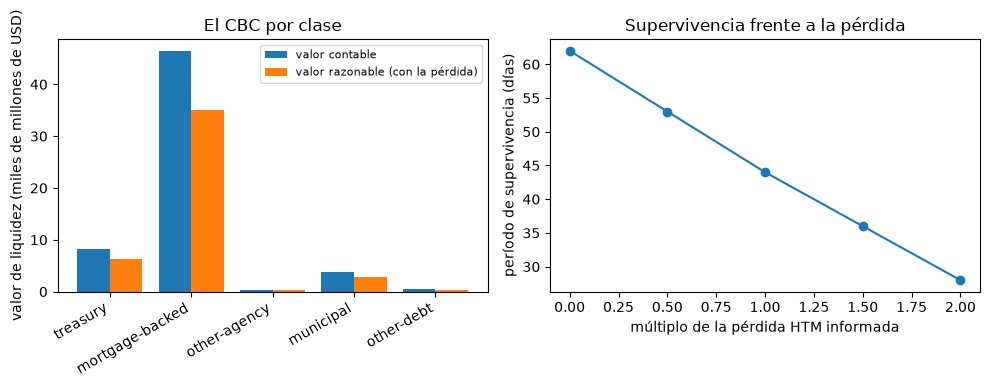

In [11]:
# Dibujar la CBC por clase con y sin la pérdida, y el período de supervivencia contra el múltiplo de pérdida
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))

names = [c["class_id"] for c in classes if c["class_id"] != "cash-and-balances"]
position = np.arange(len(names))
carrying_values = [carrying[k]["liquidity_value"] / 1e6 for k in names]
fair_values = [next(c for c in htm_out["cbc"]["classes"] if c["class_id"] == k)["liquidity_value"] / 1e6 for k in names]
left.bar(position - 0.2, carrying_values, width=0.4, label="valor contable")
left.bar(position + 0.2, fair_values, width=0.4, label="valor razonable (con la pérdida)")
left.set_xticks(position)
left.set_xticklabels(names, rotation=30, ha="right")
left.set_ylabel("valor de liquidez (miles de millones de USD)")
left.set_title("El CBC por clase")
left.legend(fontsize=8)

right.plot([row["multiple"] for row in grid], [row["survival"]["day"] for row in grid], marker="o")
right.set_xlabel("múltiplo de la pérdida HTM informada")
right.set_ylabel("período de supervivencia (días)")
right.set_title("Supervivencia frente a la pérdida")
fig.tight_layout()
plt.show()

## Resultados

- **Valores de liquidez.** Las seis clases dan un valor de liquidez total de 71,6726 mil millones de USD y el motor reproduce cada clase. Los valores respaldados por hipotecas tienen 46,364 mil millones de él, después de que 43,164 de sus 91,460 mil millones queden gravados: los valores pignorados son 0,4719 de la cartera de valores y salen del CBC.
- **Reglas de recorte.** Cuatro clases toman el margen de la Reserva Federal (recortes de 0,02 a 0,05), el efectivo está a valor nominal, y la clase de otra deuda, que no tiene margen, cae en el respaldo de 50%. La etiqueta de regla de cada clase es igual a la del documento. La prueba de recortes sobre los nueve casos construidos es verde con una diferencia máxima de 0,0, como en la fila versionada.
- **El CBC por día.** Bajo el calendario del documento el CBC es 35,84 mil millones el día 1 y los 71,67 mil millones completos desde el día 5; bajo la cota inmediata es 71,67 desde el día 1, y bajo la cota lenta es 17,92, 43,00 y 71,67 los días 1, 5 y 10. El calendario mueve los primeros días, no el total, y es una convención: el dosier nombra la capacidad por día y no da un valor.
- **La pérdida HTM.** Aplicar a prorrata la pérdida informada de la cartera a vencimiento (15,159 mil millones) quita 14,4785 mil millones de CBC, 0,202009 del total (de 71,6726 a 57,1941), 11,347 mil millones de ellos en valores respaldados por hipotecas. El período de supervivencia cae de 62 a 44 días, y cada medio paso de la pérdida cuesta 8 o 9 días. La prueba es verde porque el efecto tiene el signo esperado; el motor y la fila versionada coinciden.
- **La revaluación.** La revaluación del motor de la cartera HTM, 71,900 mil millones, está 4,268 mil millones bajo el valor razonable informado de 76,168 mil millones: 0,281548 de la pérdida no realizada informada, rojo bajo las compuertas de 0,05 y 0,15, igual que la fila versionada. El contrafactual a la par (la valoración anunciada el 2023-03-12, después de la corrida) habría subido el CBC en 2,111 mil millones hasta 73,783 mil millones. La luz roja dice que el modelo y la cifra informada discrepan, así que la pérdida usada arriba es en sí incierta; el modelo valora un bono a la par por tramo de vencimiento, una simplificación, de modo que no es un hallazgo sobre las cuentas del banco.

Lo que este cuaderno no muestra: el lado de salidas de la NLP (cuadernos 02 y 04) ni la vista LCR de los mismos activos (cuaderno 05). La pérdida HTM se reparte a prorrata por tipo porque el reporte de llamada no da ninguna por tipo; los períodos de supervivencia son propiedades de un comportamiento sintético.

## Resumen

- El valor de liquidez de un activo es $(M-E)(1-h)$; la regla que dio el recorte es parte del resultado, y el motor devuelve su etiqueta.
- El CBC no es la suma de los valores de liquidez el día 1: sigue un calendario de monetización, una convención declarada con una cota inmediata y una lenta.
- La pérdida no realizada de una cartera mantenida a vencimiento quita CBC y días de supervivencia, y el efecto crece con la pérdida.
- La revaluación propia del motor de la cartera HTM no reproduce el valor razonable informado dentro de la compuerta del producto: la cifra informada es un insumo por probar, no un dato.

**Qué probar a continuación.** Cambia el múltiplo de la grilla a 3 y mira el período de supervivencia; luego sigue con el cuaderno 04, donde el lado de salidas se compone en escenarios.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), paragraphs 63, 73 and 74 and Table 2.1. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- Federal Reserve discount window, securities margins in force from 2022-03-14 to 2023-03-12. https://www.frbdiscountwindow.org/generalpages/historical_margins/2022/03142022_03122023_securities_table
- Jiang, E. X., Matvos, G., Piskorski, T. and Seru, A. (2024), Monetary tightening and U.S. bank fragility in 2023: mark-to-market losses and uninsured depositor runs?, Journal of Financial Economics 159. https://doi.org/10.1016/j.jfineco.2024.103899